In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
#1 import database
conn = sqlite3.connect("customer_churn.db") 
sql_query =""" 
        SELECT name 
        FROM sqlite_master
        WHERE type='table'
"""
tables = pd.read_sql(sql_query, conn)
excel_file = 'customer_churn_data_raw.xlsx'

#create dataframe
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}",conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [3]:
conn = sqlite3.connect('customer_churn.db')
for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    #get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

#close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [4]:
#2. data cleaning

In [5]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [7]:
#rename col -name
#drop columns- interset and pincode
#change data type - dob
#data standardization - gender
#fix missing values - country


In [8]:
#rename col - name
df_db_customer.rename(columns= {'name':'customer_name'}, inplace = True)

In [9]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [10]:
#drop - interset and pincode
df_db_customer.drop(df_db_customer.columns[6:],axis=1, inplace=True)

In [11]:
df_db_customer.tail()

,customerid,customer_name,country,state,gender,dob
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00


In [12]:
#change data type-dob
df_db_customer['dob']= pd.to_datetime(df_db_customer['dob'])

In [13]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [14]:
#data standardization
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female', 'Women', 'Men']
Length: 4, dtype: str

In [15]:
df_db_customer['gender']=df_db_customer['gender'].replace({'Men':'Male','Women':'Female'})

In [16]:
#fix missing values
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [17]:
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country']= df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping)) 

In [18]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [19]:
df_db_subscription.info()


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [20]:
date_col= ['subscription_start_date','renewal_date','cancellation_date']
df_db_subscription[date_col]= df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [21]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [22]:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [23]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customerid      9 non-null      str  
 1   complaint_date  9 non-null      str  
 2   escalations     9 non-null      str  
 3   csat_score      9 non-null      int64
dtypes: int64(1), str(3)
memory usage: 420.0 bytes


In [24]:
df_db_support['complaint_date']= pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [25]:
#3. Feature engineering and data anaylsis

In [26]:
#creating new column
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [27]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
df= (df_db_subscription.merge(df_db_customer,on ='customerid',how='left')
                  .merge(df_db_support,on ='customerid',how='left'))

In [29]:
df.shape

(23, 20)

In [30]:
df_db_subscription['customerid'].nunique()

21

In [31]:
df_db_customer['customerid'].nunique()


21

In [32]:
df_db_support['customerid'].nunique()


7

In [33]:
df_db_support['customerid'].size

9

In [34]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [35]:
df_db_support['complaint_count'] =  df_db_support.groupby('customerid')['customerid'].transform('count')

In [36]:
df_db_support= df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep= 'last')

In [37]:
#merge df
df= (df_db_subscription
                    .merge(df_db_customer,on ='customerid',how='left')
                    .merge(df_db_support,on ='customerid',how='left'))

In [38]:
df.shape

(21, 21)

In [39]:
df.to_csv('exported_churn_data.csv',index=False)

In [40]:
#data anaylysis

In [41]:
#1churn rate

In [42]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [43]:
churn_rate =df['churn_flag'].mean()*100
print("churn rate=",round(churn_rate,2),"%")

churn rate= 28.57 %


In [44]:
#2.Retenion Rate
retenion_rate= 100 - churn_rate
print("Retenion rate=",round(retenion_rate,2),"%")

Retenion rate= 71.43 %


In [45]:
#3. churn by plan type
churn_by_plan= (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print("Churn By Plan=",churn_by_plan)

Churn By Plan=   plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [46]:
#4 a . Churn by state
churn_by_state= (df.groupby('state')['churn_flag'].mean().mul(100).round(2).reset_index())
print(churn_by_state)
count_users= df['customer_name'].count()
sum_revenue= df['monthly_charges'].sum()
print("Count of Users=",count_users," Sum of Revenue=",sum_revenue) 

           state  churn_flag
0          Delhi       25.00
1      Karnataka      100.00
2      Kathmandu        0.00
3    Maharashtra        0.00
4      Meghalaya       66.67
5       Nagaland        0.00
6      Rajasthan        0.00
7      Telangana       50.00
8  Uttar Pradesh        0.00
Count of Users= 21  Sum of Revenue= 395.78999999999996


In [47]:
#4b. churn by subscription type
churn_by_subscription_type= (df.groupby('subscription_type')['churn_flag'].mean().mul(100).round(2).reset_index())
print(churn_by_subscription_type)


  subscription_type  churn_flag
0           Organic        0.00
1              Paid       16.67
2          Refferal       83.33


In [48]:
#5. ARPU- Avg Revenue
arpu = df['monthly_charges'].mean()
print('ARPU = ',round(arpu,2))

ARPU =  18.85


In [49]:
df.columns


Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [50]:
#6. Avg Customer Tenure
#count of days users has used our service: cancellation date else cureent date
today = pd.Timestamp.today()
df['tenure_days']= np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date']- df['subscription_start_date']).dt.days,
    (today- df['subscription_start_date']).dt.days
)
avg_tenure = df['tenure_days'].mean()
print("Avg Tenure",avg_tenure)
df.head()

Avg Tenure 1572.2857142857142


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN,2056.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0,1501.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN,1441.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN,2731.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0,419.0


In [51]:
#making age 
# df['age']= np.where(
#     df['dob'].notna(),
#     ((today - df['dob']).dt.days / 365.25).astype(int),
#     print("NO")
# )
# df.head()

In [52]:
#7. revenue at risk - revenue last from churned users
revenue_at_risk= df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("revenue at risk (Rs 'K')=",revenue_at_risk)

revenue at risk (Rs 'K')= 73.94


In [53]:
#8. Esclation Rate
escalation_rate =(df['escalations'] == 'Y').mean()*100
print("escalation rate=",round(escalation_rate,2),"%")

escalation rate= 19.05 %


In [54]:
#9. Avg complaint per user
avg_complaints=df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Complaints Per User=", round(avg_complaints, 2))

Avg Complaints Per User= 0.43


In [55]:
#10. Correaltion Escalation vs churn

#encoding string to int type
df['escalations']= np.where(df['escalations'] == 'Y', 1,0)

corr_df =df[['escalations','churn_flag']].dropna()
correlation= corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between escalation vs churn is :",correlation)

Correlation between escalation vs churn is : 0.7669649888473702


In [56]:
# 11 .churn risk - create a column using existing col
conditions= [
    (df['churn_score'] < 50),
    (df['churn_score'] >=50) & (df['churn_score']<70),
    (df['churn_score'] >=70)
]
choices = ['low','med','high']
df['churn_risk']= np.select(conditions,choices, default='unkown')

In [57]:
df[['churn_risk','churn_score']].tail()


,churn_risk,churn_score
16,med,62
17,low,27
18,high,99
19,low,7
20,low,47


In [58]:
#4. Visualization using Matplotlib

In [59]:
df_visual = df.copy()

In [60]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

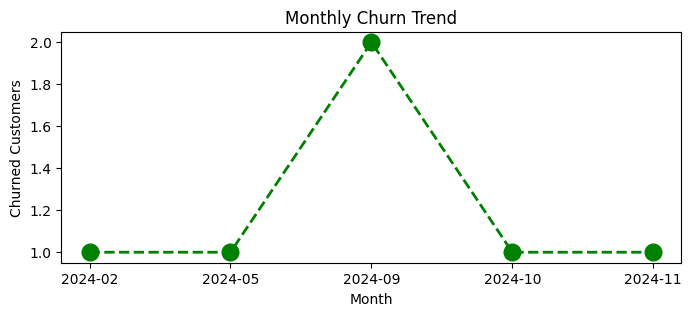

In [66]:
#4.1 Monthly churn Trend (Time series KPI)
df_visual['cancellation_month']= df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()
plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype('str'),churn_trend.values,color='green', marker='o', linestyle='dashed',linewidth=2, markersize=12)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

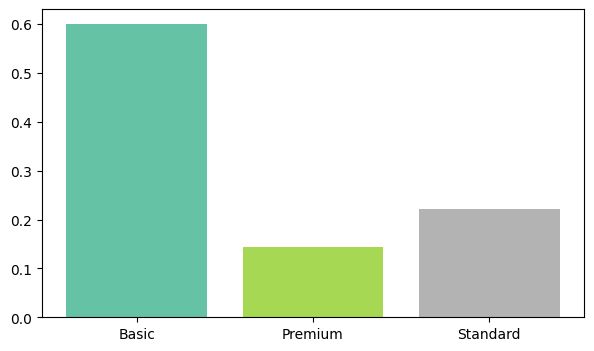

In [75]:
#4.2 churn by plan type
churn_plan= df_visual.groupby('plan_type')['churn_flag'].mean()
# color= ['green','red','purple']
colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(7,4))

plt.bar(churn_plan.index,churn_plan.values, color= colors)
plt.show()

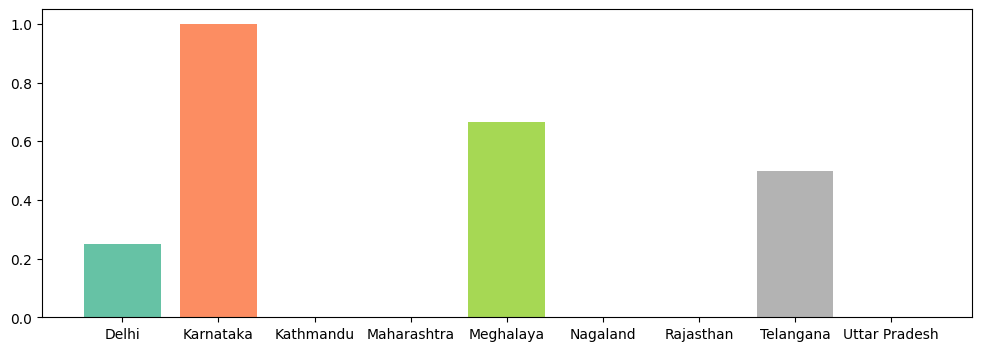

In [77]:
#4.3 Churn by stress
churn_plan= df_visual.groupby('state')['churn_flag'].mean()
# color= ['green','red','purple']
colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(12,4))

plt.bar(churn_plan.index,churn_plan.values, color= colors)
plt.show()

In [ ]:
#visualization using seaborn

In [78]:
#encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [79]:
#df_encoded = 
df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [100]:
#incorrect method of encoding - as number are not assigned based on priorty
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()
categorial_cols= ['plan_type','contract_type','churn_risk']

for col in categorial_cols:
    df_encoded[col]=df_encoded[col].astype('category').cat.codes

In [101]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,1
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,1


In [99]:
import warnings
warnings.filterwarnings("ignore")

<Axes: >

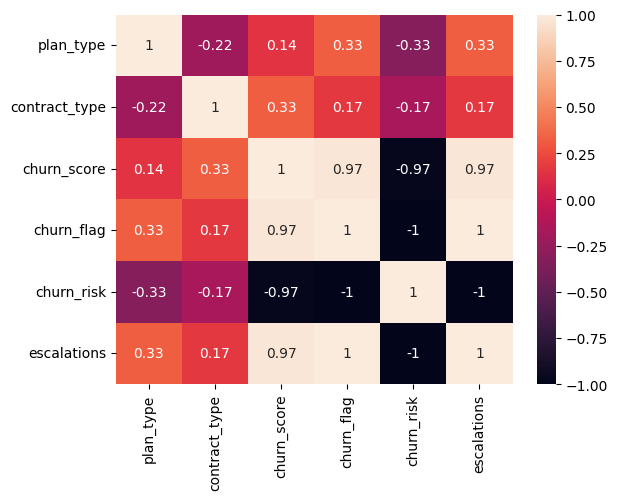

In [102]:
#heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot = True)

In [107]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str
churn_risk : <StringArray>
['low', 'high', 'med']
Length: 3, dtype: str


In [108]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [109]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

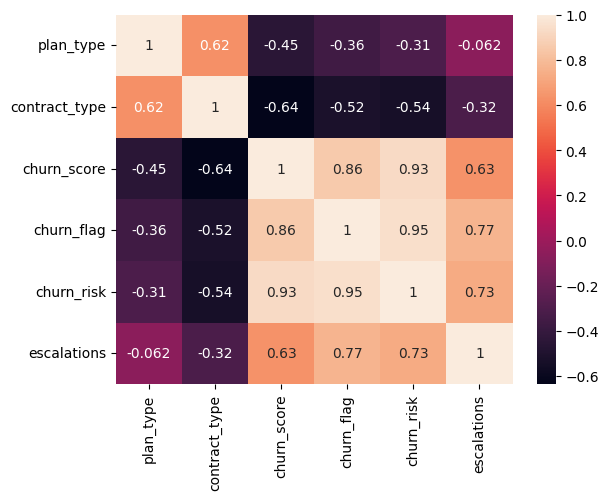

In [110]:
#heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot = True)

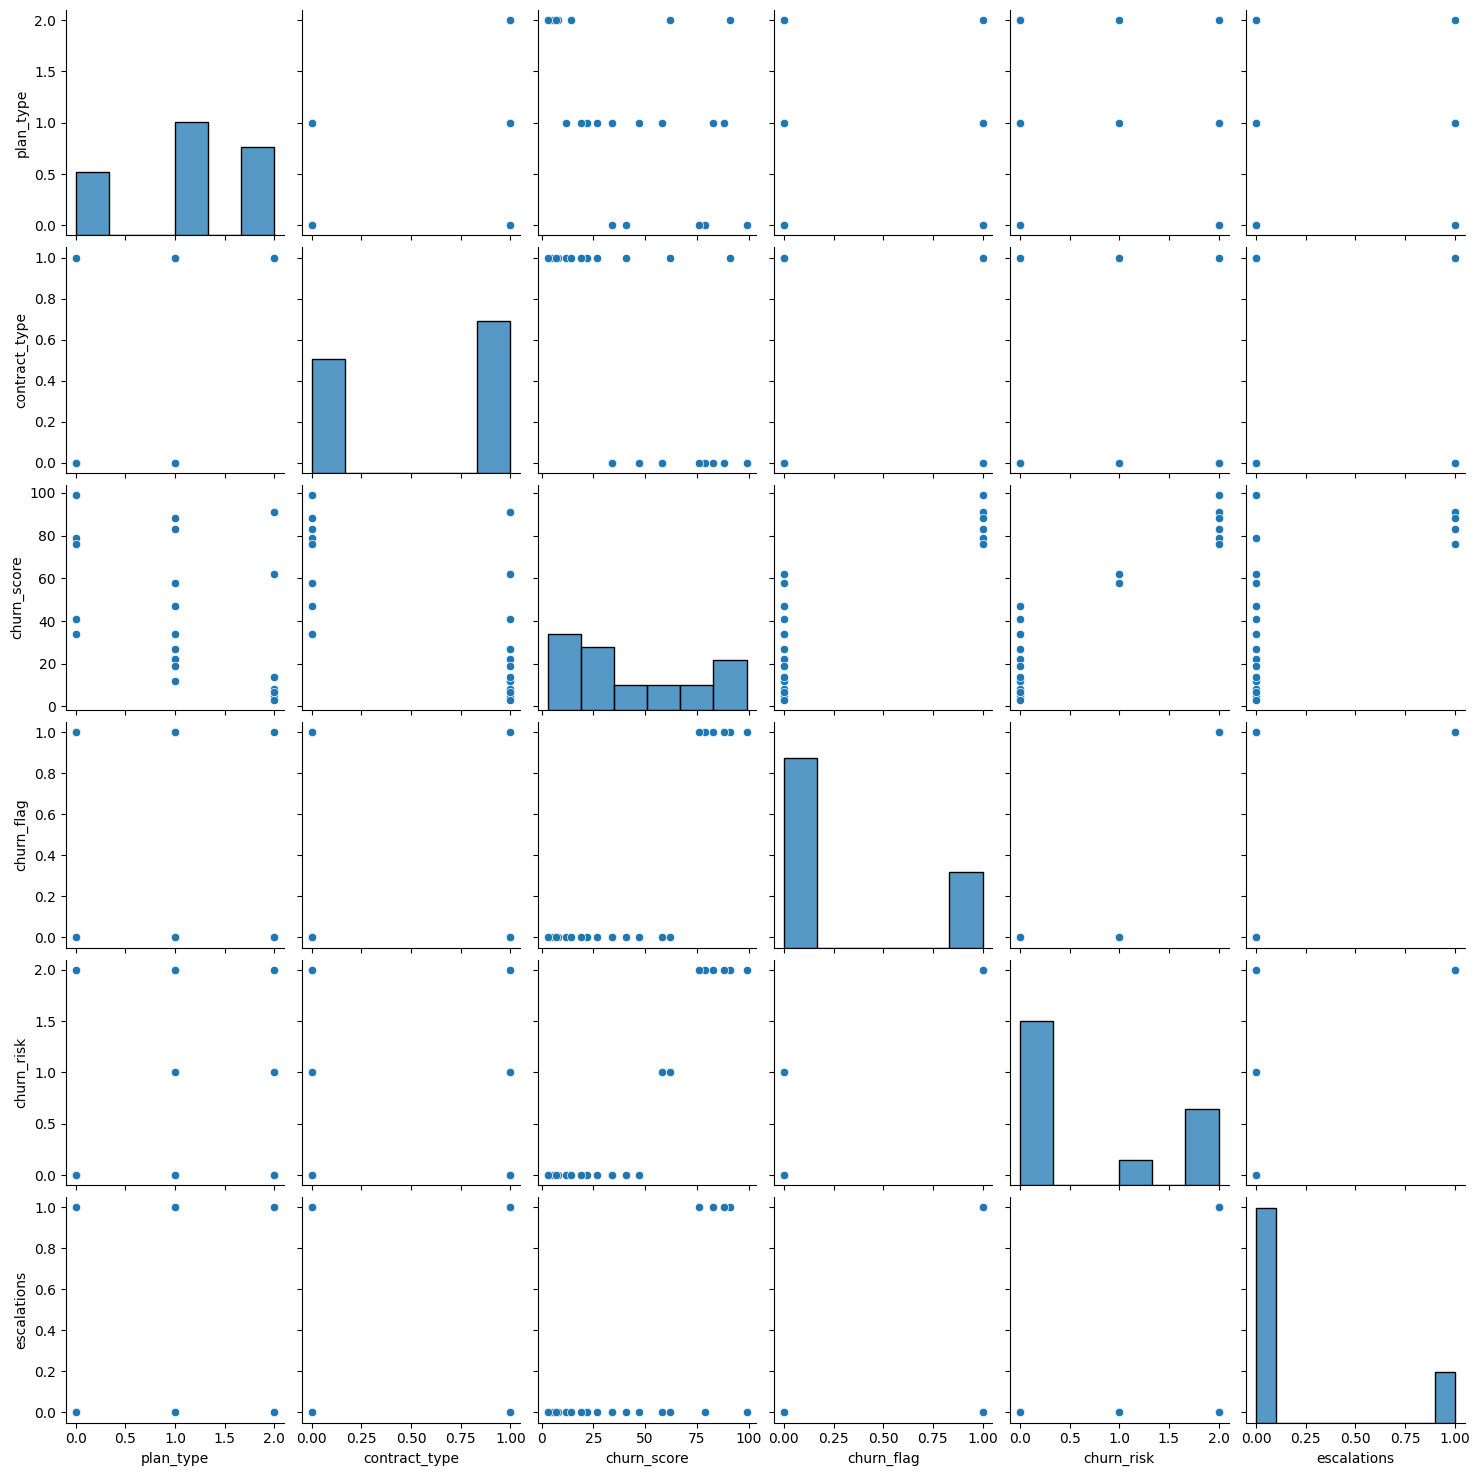

In [112]:
# - relationship in dataset
sns.pairplot(df_encoded)

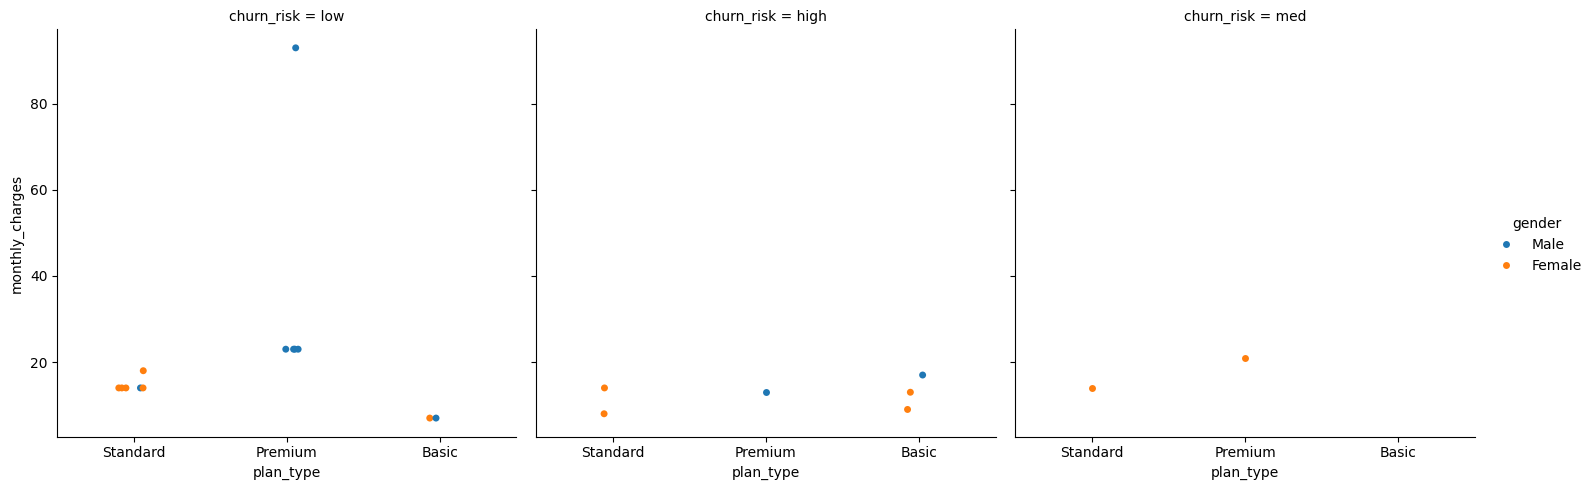

In [113]:
#catplt/Facegrid plot - multi-dim comparision
sns.catplot(data = df_visual,
           x='plan_type',
           y='monthly_charges',
           hue='gender',
           col='churn_risk')

In [114]:
#pivot table 

In [116]:
pd.pivot_table(
    df_visual,
    values= 'churn_flag',
    index='plan_type',
    aggfunc = 'mean'
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [118]:
pd.pivot_table(
    df_visual,
    values= ['churn_flag','monthly_charges'],
    index='plan_type',
    aggfunc = {
        'monthly_charges':'sum',
        'customerid':'nunique',
        'churn_flag':'mean'
    }
)

KeyError: "Label(s) ['customerid'] do not exist"

In [ ]:
df_visuals.col